# Substructure Analysis: 104 + 66 Caspase-Active Compounds (Kneedle eps)

**Section 1** — 104 compounds from the fully-tested set (all 14 cell lines), active in ≥1 cell line  
**Section 2** — 66 compounds tested only in CHO-K1 + HepG2, active in both  
**Section 3** — Combined 170 compounds: shared structural families across both groups

**Pipeline per group:**
1. ECFP4 Morgan fingerprints (radius=2, 2048 bits)
2. UMAP projection (Jaccard metric) — dimensionality reduction preserving local Jaccard neighbourhood structure (McInnes et al. 2018)
3. k-NN distance plot on UMAP embedding → **eps auto-detected via Kneedle algorithm** (Satopaa et al. 2011)
4. DBSCAN on UMAP embedding (Euclidean) → structural clusters (Ester et al. 1996)
5. MCS core per cluster via `rdFMCS.FindMCS`; 3–5 most central representatives per cluster

**References:**
- Ester et al. (1996) DBSCAN, KDD
- McInnes et al. (2018) UMAP, arXiv
- Schubert et al. (2017) DBSCAN Revisited, ACM TKDD
- Satopaa et al. (2011) Finding a Kneedle in a Haystack, ICDCS
- Bajusz et al. (2015) Tanimoto/Jaccard, J. Cheminform.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from rdkit import Chem, DataStructs
from rdkit.Chem import Draw, rdFingerprintGenerator, rdFMCS
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from kneed import KneeLocator
import umap
import warnings
warnings.filterwarnings('ignore')

BASE = '/Users/yaminichitikela/Documents/casepase/Casepase-activation/'
gen  = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

def to_fp_matrix(mols):
    fps = [gen.GetFingerprint(m) for m in mols]
    return fps, np.array([list(fp.ToBitString()) for fp in fps], dtype=np.float32)

def plot_umap(fp_matrix, labels, title='UMAP', color_map=None, annotate=None):
    n = len(fp_matrix)
    reducer = umap.UMAP(n_neighbors=min(15, n - 1),
                        min_dist=0.3, metric='jaccard', random_state=42)
    emb = reducer.fit_transform(fp_matrix)
    unique = list(dict.fromkeys(labels))
    if color_map is None:
        color_map = {l: plt.cm.tab10(i % 10) for i, l in enumerate(unique)}
    fig, ax = plt.subplots(figsize=(8, 6))
    for lbl in unique:
        mask = np.array([l == lbl for l in labels])
        ax.scatter(emb[mask, 0], emb[mask, 1], c=[color_map[lbl]],
                   label=lbl, s=80, edgecolors='black', linewidths=0.5, alpha=0.85)
    if annotate is not None:
        for i, txt in enumerate(annotate):
            ax.annotate(str(txt), (emb[i, 0], emb[i, 1]),
                        textcoords='offset points', xytext=(4, 3), fontsize=6.5, color='#444')
    ax.legend(loc='upper left', fontsize=8.5, framealpha=0.9)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('UMAP dim 1'); ax.set_ylabel('UMAP dim 2')
    plt.tight_layout(); plt.show()
    return emb

def get_mcs_core(mols):
    """Return MCS core mol, or None if <2 mols or no common core found."""
    if len(mols) < 2:
        return None
    mcs = rdFMCS.FindMCS(mols, ringMatchesRingOnly=True,
                         completeRingsOnly=True, timeout=10)
    if mcs and mcs.numAtoms > 0:
        return Chem.MolFromSmarts(mcs.smartsString)
    return None

def draw_cluster_reps(dataset, name_map, title, mols_per_row=5, img_size=(280, 230),
                      max_per_cluster=12):
    """Draw one representative + MCS core per cluster."""
    from IPython.display import display
    import pubchempy as pcp

    reps, legs, highlights = [], [], []
    cl_name_map = {}
    print(f'Fetching PubChem names for {title}...')

    for cl in sorted(c for c in dataset['cluster'].unique() if c != -1):
        sub   = dataset[dataset['cluster'] == cl].reset_index(drop=True)
        fps   = sub['fp'].tolist()
        avg   = [sum(DataStructs.BulkTanimotoSimilarity(fp, fps)) for fp in fps]
        rep   = sub.loc[int(np.argmax(avg))]
        cid   = int(rep['PUBCHEM_CID'])
        try:
            c_   = pcp.Compound.from_cid(cid)
            syns = c_.synonyms or []
            short = [s for s in syns if len(s) <= 30 and s[0].isalpha()]
            name  = short[0] if short else (syns[0][:28] if syns else str(cid))
        except Exception:
            name = str(cid)
        cl_name_map[cl] = name

        cluster_mols = sub.head(max_per_cluster)['mol'].tolist()
        core = get_mcs_core(cluster_mols)
        if core is not None:
            reps.append(core)
            legs.append(f'C{cl} (n={len(sub)}) ★ Core ★')
            highlights.append([])

        reps.append(rep['mol'])
        legs.append(f'C{cl} (n={len(sub)})\n{name} [CID {cid}]')
        match = rep['mol'].GetSubstructMatch(core) if core is not None else []
        highlights.append(list(match))
        print(f'  Cluster {cl:2d} (n={len(sub):3d})  {name}  [CID {cid}]')

    if not reps:
        print('No clusters found — all compounds are structurally unique.')
        return cl_name_map

    img = Draw.MolsToGridImage(reps, molsPerRow=mols_per_row, subImgSize=img_size,
                               legends=legs, highlightAtomLists=highlights,
                               returnPNG=False)
    display(img)
    return cl_name_map

def umap_by_cluster(dataset, cl_name_map, title):
    fig, ax = plt.subplots(figsize=(9, 7))
    cmap = plt.cm.tab10
    noise = dataset[dataset['cluster'] == -1]
    ax.scatter(noise['umap_x'], noise['umap_y'], c='#cccccc',
               s=35, edgecolors='none', alpha=0.5, label=f'unique / noise (n={len(noise)})')
    for cl in sorted(c for c in dataset['cluster'].unique() if c != -1):
        sub = dataset[dataset['cluster'] == cl]
        name = cl_name_map.get(cl, f'Cluster {cl}')
        ax.scatter(sub['umap_x'], sub['umap_y'], c=[cmap(cl % 10)],
                   s=70, edgecolors='black', linewidths=0.5, alpha=0.85,
                   label=f'C{cl}: {name} (n={len(sub)})')
    for _, row in dataset.iterrows():
        ax.annotate(str(int(row['PUBCHEM_CID'])), (row['umap_x'], row['umap_y']),
                    textcoords='offset points', xytext=(4, 3), fontsize=6, color='#444')
    ax.legend(loc='upper left', fontsize=7.5, framealpha=0.95, ncol=2)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('UMAP dim 1'); ax.set_ylabel('UMAP dim 2')
    plt.tight_layout(); plt.show()

def knn_eps_plot(emb, min_samples, title):
    """
    k-NN distance plot on UMAP embedding to auto-select DBSCAN eps.
    Knee detected via Kneedle algorithm (Satopaa et al. 2011, ICDCS).
    Distances are Euclidean in the 2D UMAP embedding space.
    """
    nbrs = NearestNeighbors(n_neighbors=min_samples + 1).fit(emb)
    distances, _ = nbrs.kneighbors(emb)
    sorted_d = np.sort(distances[:, -1])[::-1]

    x = np.arange(len(sorted_d))
    knee_obj = KneeLocator(x, sorted_d, curve='convex', direction='decreasing')
    eps = float(sorted_d[knee_obj.knee]) if knee_obj.knee is not None else float(np.median(sorted_d))

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(sorted_d, 'b-', linewidth=1.5, label='k-NN distance')
    if knee_obj.knee is not None:
        ax.axvline(knee_obj.knee, color='red', linestyle='--', linewidth=1.2,
                   label=f'knee → eps = {eps:.3f}')
        ax.axhline(eps, color='red', linestyle=':', linewidth=0.8)
    ax.legend(fontsize=9)
    ax.set_xlabel('Points sorted by decreasing distance')
    ax.set_ylabel(f'Euclidean distance to {min_samples}-th nearest neighbour (UMAP space)')
    ax.set_title(f'{title}\nKneedle eps = {eps:.3f}  (min_samples={min_samples})')
    ax.grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()
    print(f'Min={sorted_d.min():.4f}  Median={np.median(sorted_d):.4f}  '
          f'Max={sorted_d.max():.4f}  →  Kneedle eps={eps:.4f}')
    return sorted_d, eps

def pick_central(sub, n_min=3, n_max=5):
    """Return n_min–n_max rows closest to cluster centroid in UMAP space."""
    coords   = sub[['umap_x', 'umap_y']].values
    centroid = coords.mean(axis=0)
    dists    = np.linalg.norm(coords - centroid, axis=1)
    n_pick   = max(n_min, min(n_max, len(sub)))
    return sub.iloc[np.argsort(dists)[:n_pick]].reset_index(drop=True)

print('Setup complete.')

Setup complete.


---
## Load Data

In [3]:
df = pd.read_csv(BASE + 'results/all_cell_line_comparisions/consistent_compounds_caspase_all.csv')
ASSAY_COLS = [c for c in df.columns if c not in ('PUBCHEM_CID', 'pattern', 'behavior')]

smi_dfs = []
for fname in os.listdir(BASE + 'cleaned_datasets'):
    if not fname.endswith('.csv'):
        continue
    try:
        tmp = pd.read_csv(BASE + 'cleaned_datasets/' + fname,
                          usecols=['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES'],
                          low_memory=False)
        smi_dfs.append(tmp)
    except Exception:
        pass

smiles_df = (pd.concat(smi_dfs)
               .dropna(subset=['PUBCHEM_EXT_DATASOURCE_SMILES'])
               .drop_duplicates('PUBCHEM_CID')
               .reset_index(drop=True))
print(f'SMILES lookup: {len(smiles_df)} unique compounds')

fully_tested = df[df[ASSAY_COLS].notna().all(axis=1)].copy()
fully_tested['n_active'] = (fully_tested[ASSAY_COLS] == 'Active').sum(axis=1)
cids_104 = fully_tested[fully_tested['n_active'] >= 1]['PUBCHEM_CID'].tolist()
print(f'Group 104: {len(cids_104)} compounds (fully tested, active in ≥1 of 14 cell lines)')

cids_66 = df[df['behavior'] == 'Active']['PUBCHEM_CID'].tolist()
print(f'Group 66:  {len(cids_66)} compounds (CHO-K1 + HepG2 active, not tested elsewhere)')
print(f'Overlap:   {len(set(cids_104) & set(cids_66))} (should be 0)')

SMILES lookup: 8777 unique compounds
Group 104: 104 compounds (fully tested, active in ≥1 of 14 cell lines)
Group 66:  66 compounds (CHO-K1 + HepG2 active, not tested elsewhere)
Overlap:   0 (should be 0)


---
## Section 1 — 104 Compounds: Fully-Tested, Active in ≥1 Cell Line

These 104 compounds were tested in **all 14 cell lines** and showed caspase activation in at least one.
Colour-coded by how many cell lines each compound activated.

In [4]:
g104 = (pd.DataFrame({'PUBCHEM_CID': cids_104})
          .merge(smiles_df, on='PUBCHEM_CID', how='left'))
g104 = g104.merge(
    fully_tested[['PUBCHEM_CID', 'n_active']], on='PUBCHEM_CID', how='left')
g104['mol'] = g104['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(
    lambda s: Chem.MolFromSmiles(s) if pd.notna(s) else None)
g104 = g104[g104['mol'].notna()].reset_index(drop=True)

def activity_bin(n):
    if n == 1:  return '1 cell line'
    if n <= 3:  return '2-3 cell lines'
    if n <= 7:  return '4-7 cell lines'
    return '8+ cell lines (pan-toxic)'

g104['activity_bin'] = g104['n_active'].apply(activity_bin)
g104['fp'], fp_matrix_104 = to_fp_matrix(g104['mol'].tolist())

print(g104['activity_bin'].value_counts())
print(f'\n{len(g104)} compounds with valid SMILES')

activity_bin
1 cell line                  62
2-3 cell lines               25
4-7 cell lines               13
8+ cell lines (pan-toxic)     4
Name: count, dtype: int64

104 compounds with valid SMILES


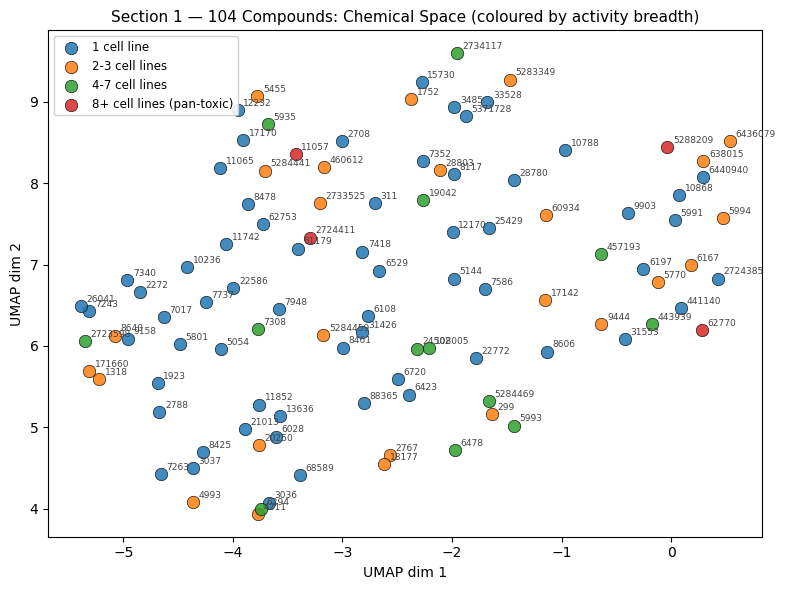

In [5]:
color_map_104 = {
    '1 cell line':               '#1f77b4',
    '2-3 cell lines':            '#ff7f0e',
    '4-7 cell lines':            '#2ca02c',
    '8+ cell lines (pan-toxic)': '#d62728',
}

emb_104 = plot_umap(
    fp_matrix_104,
    labels    = g104['activity_bin'].tolist(),
    title     = 'Section 1 — 104 Compounds: Chemical Space (coloured by activity breadth)',
    color_map = color_map_104,
    annotate  = g104['PUBCHEM_CID'].astype(int),
)
g104['umap_x'], g104['umap_y'] = emb_104[:, 0], emb_104[:, 1]

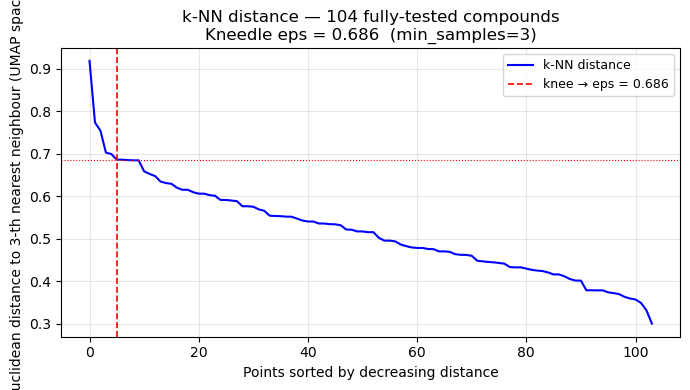

Min=0.3002  Median=0.5152  Max=0.9180  →  Kneedle eps=0.6857

Using EPS_104 = 0.6857 (Kneedle)


In [6]:
# k-NN distance plot — eps auto-detected via Kneedle (Satopaa et al. 2011)
# Euclidean distances in the 2D UMAP embedding space.
MIN_SAMPLES = 3
knn_sorted_104, EPS_104 = knn_eps_plot(emb_104, MIN_SAMPLES,
                                       'k-NN distance — 104 fully-tested compounds')
print(f'\nUsing EPS_104 = {EPS_104:.4f} (Kneedle)')

In [7]:
db_104 = DBSCAN(eps=EPS_104, min_samples=MIN_SAMPLES).fit(emb_104)
g104['cluster'] = db_104.labels_
n_cl_104 = len(set(db_104.labels_)) - (1 if -1 in db_104.labels_ else 0)
print(f'DBSCAN (104): {n_cl_104} clusters  |  '
      f'{(db_104.labels_ == -1).sum()} noise points  |  eps={EPS_104:.4f}')
print(pd.Series(db_104.labels_).value_counts().sort_index())

DBSCAN (104): 1 clusters  |  0 noise points  |  eps=0.6857
0    104
Name: count, dtype: int64


Fetching PubChem names for 104 fully-tested active compounds...
  Cluster  0 (n=104)  Clorophene  [CID 8425]


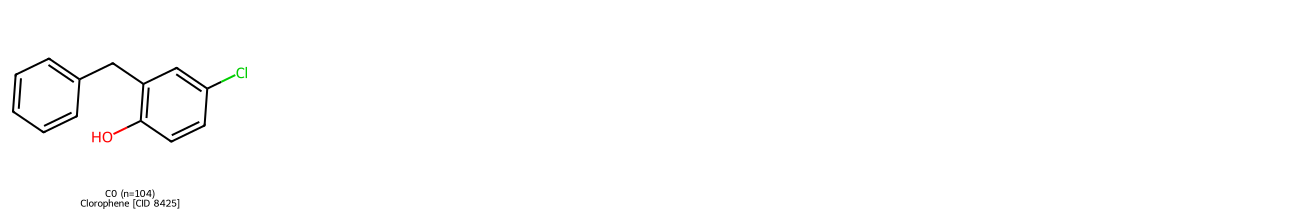

In [8]:
cl_name_104 = draw_cluster_reps(
    g104, {}, title='104 fully-tested active compounds',
    mols_per_row=5, img_size=(260, 220))

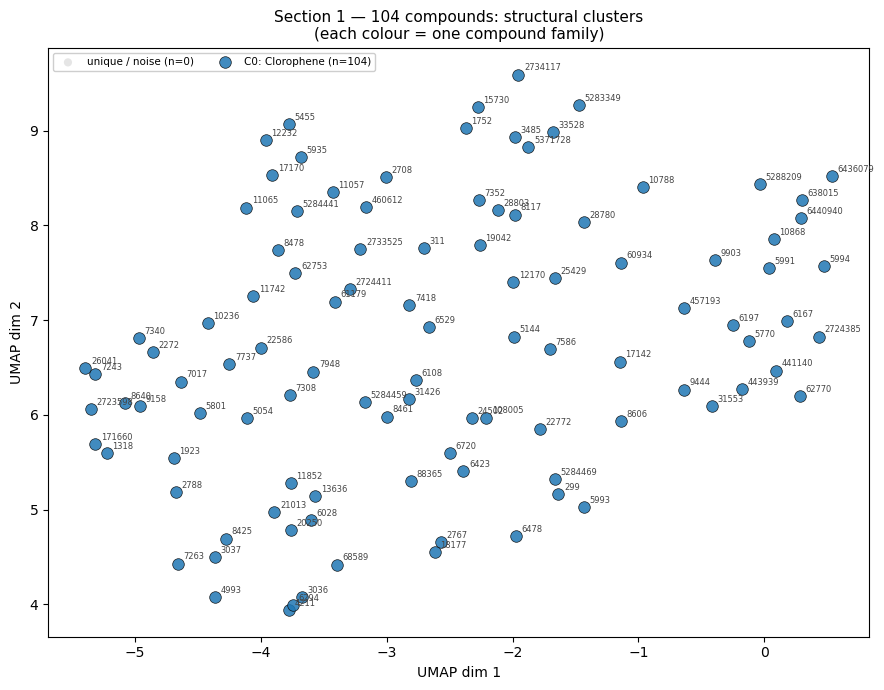

In [9]:
umap_by_cluster(
    g104, cl_name_104,
    title='Section 1 — 104 compounds: structural clusters\n(each colour = one compound family)')

### Section 1 — MCS Core Detail per Cluster (3–5 most central representatives)

Drawing 6 panels across 1 cluster(s)


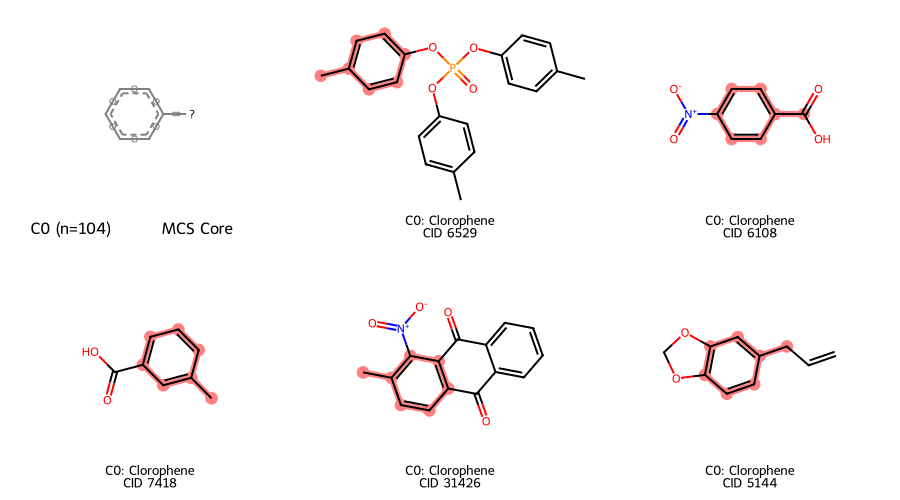

In [10]:
from IPython.display import display

CLUSTERS     = None   # None = all; or e.g. [0, 1, 2]
MOLS_PER_ROW = 3

cluster_ids = sorted(c for c in g104['cluster'].unique() if c != -1)
if CLUSTERS is not None:
    cluster_ids = [c for c in cluster_ids if c in CLUSTERS]

mols, legends, highlights = [], [], []

for cl in cluster_ids:
    sub   = g104[g104['cluster'] == cl].reset_index(drop=True)
    shown = pick_central(sub)
    core  = get_mcs_core(shown['mol'].tolist())
    name  = cl_name_104.get(cl, f'Cluster {cl}')

    if core is not None:
        mols.append(core)
        legends.append(f'C{cl} (n={len(sub)}) ★ MCS Core ★')
        highlights.append([])

    for _, row in shown.iterrows():
        mol = row['mol']
        mols.append(mol)
        legends.append(f'C{cl}: {name}\nCID {int(row["PUBCHEM_CID"])}')
        match = mol.GetSubstructMatch(core) if core is not None else []
        highlights.append(list(match))

print(f'Drawing {len(mols)} panels across {len(cluster_ids)} cluster(s)')
if mols:
    img = Draw.MolsToGridImage(mols, molsPerRow=MOLS_PER_ROW, subImgSize=(300, 250),
                               legends=legends, highlightAtomLists=highlights,
                               returnPNG=False)
    display(img)

---
## Section 2 — 66 Compounds: CHO-K1 + HepG2 Active

In [11]:
g66 = (pd.DataFrame({'PUBCHEM_CID': cids_66})
         .merge(smiles_df, on='PUBCHEM_CID', how='left'))
g66['mol'] = g66['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(
    lambda s: Chem.MolFromSmiles(s) if pd.notna(s) else None)
g66 = g66[g66['mol'].notna()].reset_index(drop=True)
g66['fp'], fp_matrix_66 = to_fp_matrix(g66['mol'].tolist())
print(f'{len(g66)} compounds with valid SMILES (out of 66)')

66 compounds with valid SMILES (out of 66)


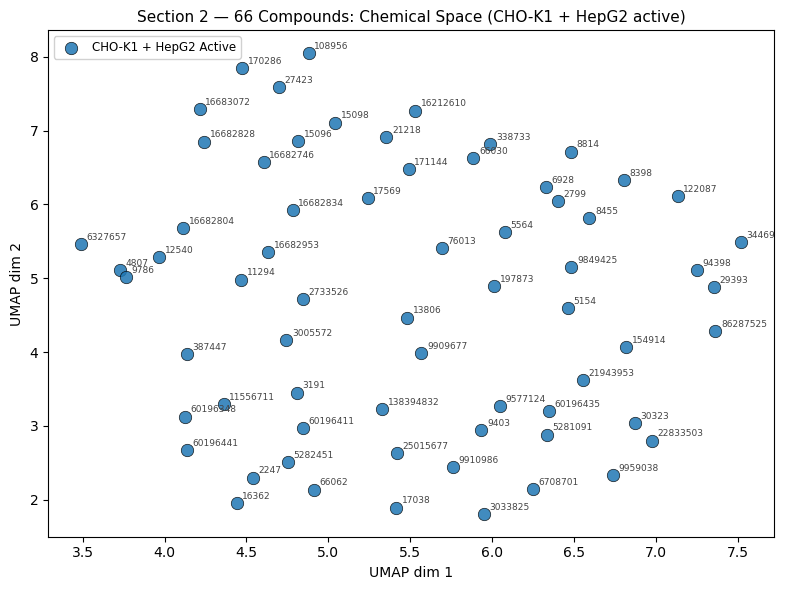

In [12]:
emb_66 = plot_umap(
    fp_matrix_66,
    labels   = ['CHO-K1 + HepG2 Active'] * len(g66),
    title    = 'Section 2 — 66 Compounds: Chemical Space (CHO-K1 + HepG2 active)',
    annotate = g66['PUBCHEM_CID'].astype(int),
)
g66['umap_x'], g66['umap_y'] = emb_66[:, 0], emb_66[:, 1]

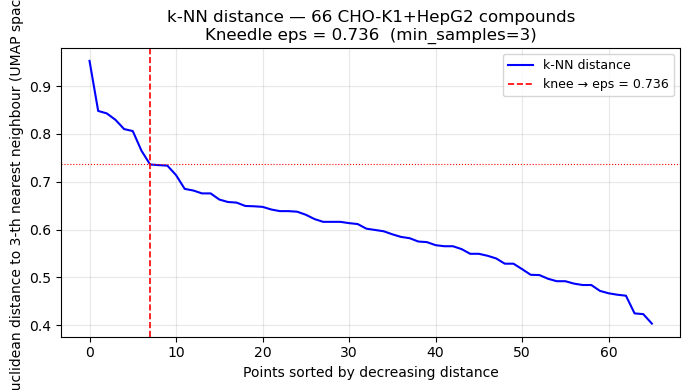

Min=0.4035  Median=0.6006  Max=0.9527  →  Kneedle eps=0.7361

Using EPS_66 = 0.7361 (Kneedle)


In [13]:
knn_sorted_66, EPS_66 = knn_eps_plot(emb_66, MIN_SAMPLES,
                                     'k-NN distance — 66 CHO-K1+HepG2 compounds')
print(f'\nUsing EPS_66 = {EPS_66:.4f} (Kneedle)')

In [14]:
db_66 = DBSCAN(eps=EPS_66, min_samples=MIN_SAMPLES).fit(emb_66)
g66['cluster'] = db_66.labels_
n_cl_66 = len(set(db_66.labels_)) - (1 if -1 in db_66.labels_ else 0)
print(f'DBSCAN (66): {n_cl_66} clusters  |  '
      f'{(db_66.labels_ == -1).sum()} noise points  |  eps={EPS_66:.4f}')
print(pd.Series(db_66.labels_).value_counts().sort_index())

DBSCAN (66): 1 clusters  |  0 noise points  |  eps=0.7361
0    66
Name: count, dtype: int64


Fetching PubChem names for 66 CHO-K1+HepG2 active compounds...
  Cluster  0 (n= 66)  TRIBUTYLTIN BENZOATE  [CID 16682834]


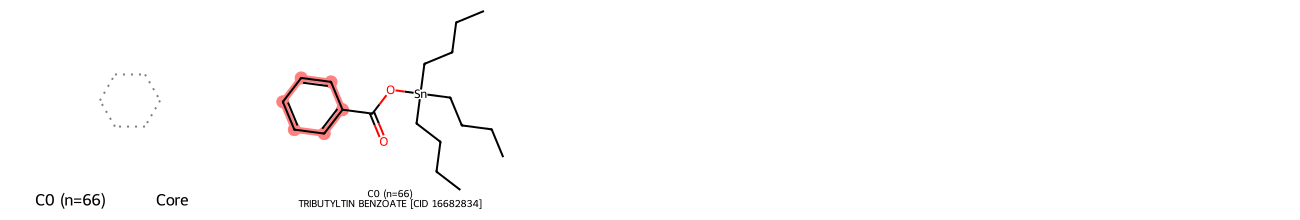

In [15]:
cl_name_66 = draw_cluster_reps(
    g66, {}, title='66 CHO-K1+HepG2 active compounds',
    mols_per_row=5, img_size=(260, 220))

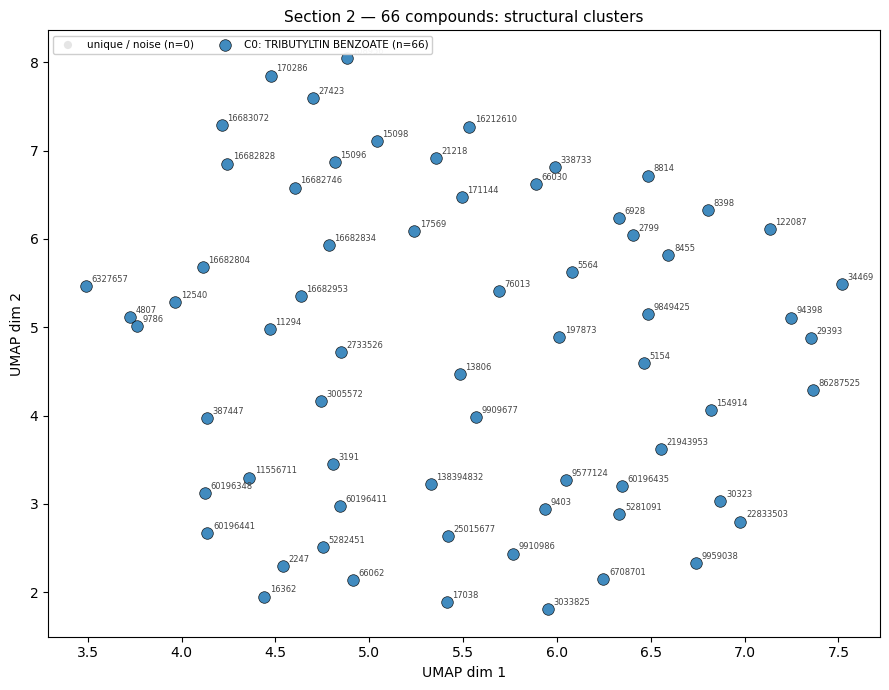

In [16]:
umap_by_cluster(
    g66, cl_name_66,
    title='Section 2 — 66 compounds: structural clusters')

### Section 2 — MCS Core Detail per Cluster (3–5 most central representatives)

Drawing 6 panels across 1 cluster(s)


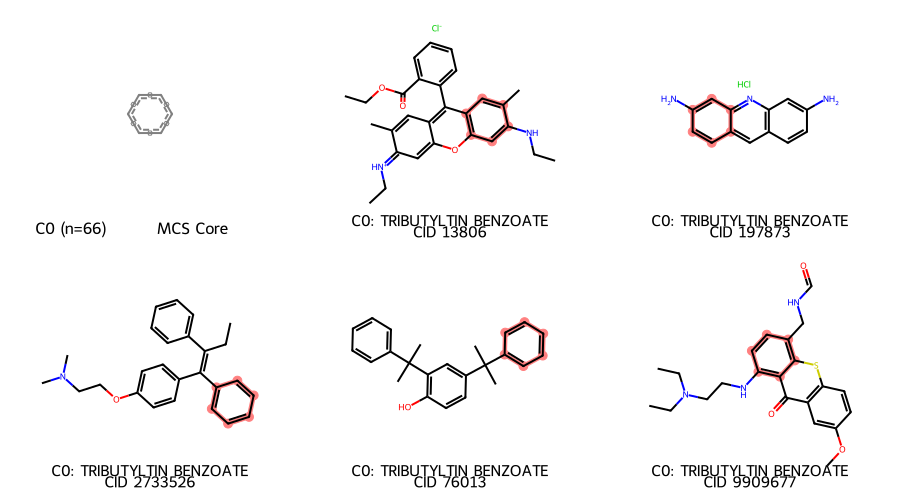

In [17]:
from IPython.display import display

CLUSTERS_66  = None
MOLS_PER_ROW = 3

cluster_ids_66 = sorted(c for c in g66['cluster'].unique() if c != -1)
if CLUSTERS_66 is not None:
    cluster_ids_66 = [c for c in cluster_ids_66 if c in CLUSTERS_66]

mols66, legs66, hi66 = [], [], []

for cl in cluster_ids_66:
    sub   = g66[g66['cluster'] == cl].reset_index(drop=True)
    shown = pick_central(sub)
    core  = get_mcs_core(shown['mol'].tolist())
    name  = cl_name_66.get(cl, f'Cluster {cl}')

    if core is not None:
        mols66.append(core)
        legs66.append(f'C{cl} (n={len(sub)}) ★ MCS Core ★')
        hi66.append([])

    for _, row in shown.iterrows():
        mol = row['mol']
        mols66.append(mol)
        legs66.append(f'C{cl}: {name}\nCID {int(row["PUBCHEM_CID"])}')
        match = mol.GetSubstructMatch(core) if core is not None else []
        hi66.append(list(match))

print(f'Drawing {len(mols66)} panels across {len(cluster_ids_66)} cluster(s)')
if mols66:
    img = Draw.MolsToGridImage(mols66, molsPerRow=MOLS_PER_ROW, subImgSize=(300, 250),
                               legends=legs66, highlightAtomLists=hi66, returnPNG=False)
    display(img)

---
## Section 3 — 170 Combined Compounds

In [18]:
g104_sub = g104[['PUBCHEM_CID', 'mol', 'fp', 'umap_x', 'umap_y']].copy()
g104_sub['group'] = '104 (fully tested)'

g66_sub = g66[['PUBCHEM_CID', 'mol', 'fp', 'umap_x', 'umap_y']].copy()
g66_sub['group'] = '66 (CHO-K1+HepG2)'

g170 = pd.concat([g104_sub, g66_sub], ignore_index=True)
_, fp_matrix_170 = to_fp_matrix(g170['mol'].tolist())
print(f'Combined: {len(g170)} compounds')

Combined: 170 compounds


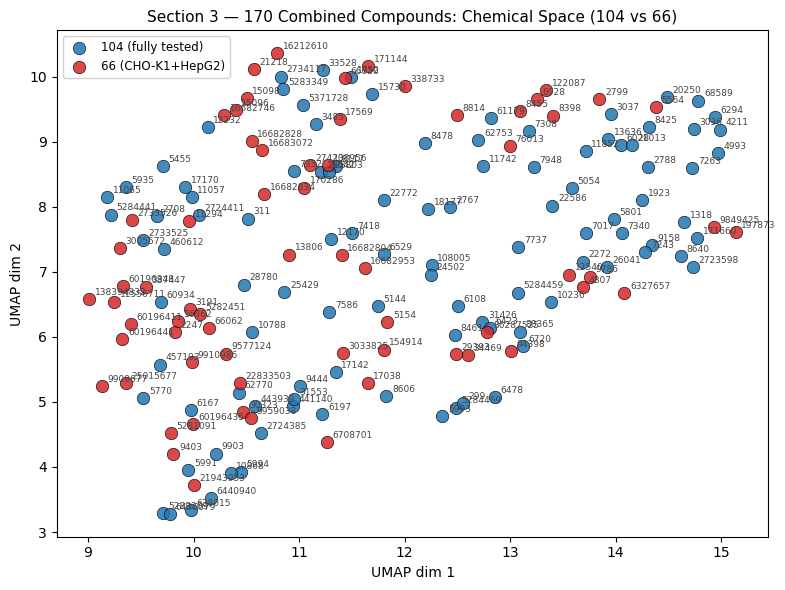

In [19]:
emb_170 = plot_umap(
    fp_matrix_170,
    labels    = g170['group'].tolist(),
    title     = 'Section 3 — 170 Combined Compounds: Chemical Space (104 vs 66)',
    color_map = {'104 (fully tested)': '#1f77b4', '66 (CHO-K1+HepG2)': '#d62728'},
    annotate  = g170['PUBCHEM_CID'].astype(int),
)
g170['umap_x'], g170['umap_y'] = emb_170[:, 0], emb_170[:, 1]

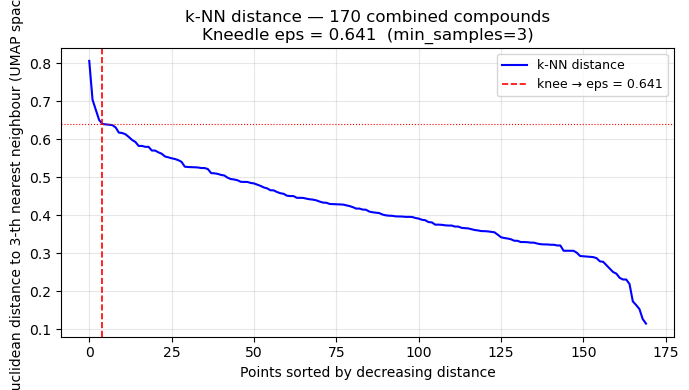

Min=0.1151  Median=0.4125  Max=0.8069  →  Kneedle eps=0.6406

Using EPS_170 = 0.6406 (Kneedle)


In [20]:
knn_sorted_170, EPS_170 = knn_eps_plot(emb_170, MIN_SAMPLES,
                                       'k-NN distance — 170 combined compounds')
print(f'\nUsing EPS_170 = {EPS_170:.4f} (Kneedle)')

In [21]:
db_170 = DBSCAN(eps=EPS_170, min_samples=MIN_SAMPLES).fit(emb_170)
g170['cluster'] = db_170.labels_
n_cl_170 = len(set(db_170.labels_)) - (1 if -1 in db_170.labels_ else 0)
print(f'DBSCAN (170): {n_cl_170} clusters  |  '
      f'{(db_170.labels_ == -1).sum()} noise points  |  eps={EPS_170:.4f}')
print(pd.Series(db_170.labels_).value_counts().sort_index())

print('\nCluster composition (both groups?):')
for cl in sorted(c for c in g170['cluster'].unique() if c != -1):
    sub  = g170[g170['cluster'] == cl]
    n104 = (sub['group'] == '104 (fully tested)').sum()
    n66  = (sub['group'] == '66 (CHO-K1+HepG2)').sum()
    mixed = ' *** MIXED ***' if n104 > 0 and n66 > 0 else ''
    print(f'  C{cl}: n={len(sub)} | 104-group={n104} | 66-group={n66}{mixed}')

DBSCAN (170): 1 clusters  |  1 noise points  |  eps=0.6406
-1      1
 0    169
Name: count, dtype: int64

Cluster composition (both groups?):
  C0: n=169 | 104-group=103 | 66-group=66 *** MIXED ***


Fetching PubChem names for 170 combined active compounds...
  Cluster  0 (n=169)  TRIBUTYLTIN BENZOATE  [CID 16682834]


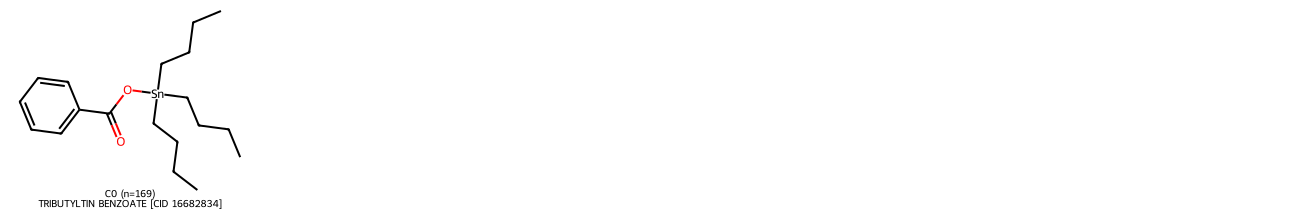

In [22]:
cl_name_170 = draw_cluster_reps(
    g170, {}, title='170 combined active compounds',
    mols_per_row=5, img_size=(260, 220))

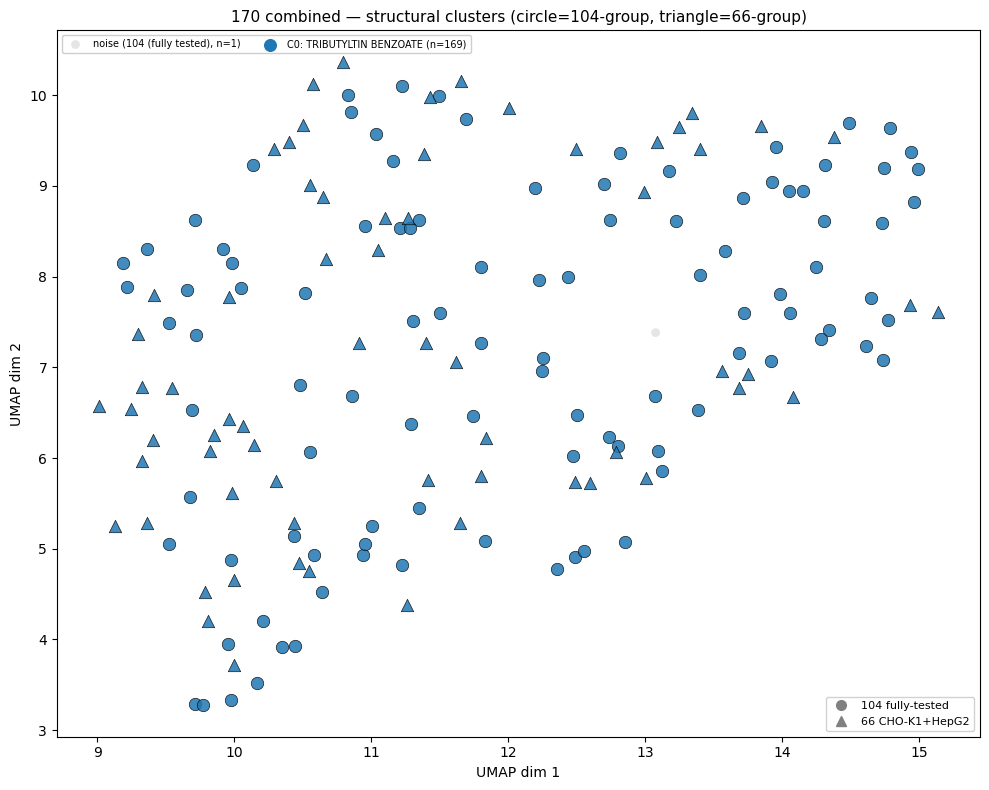

In [23]:
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(10, 8))
cmap = plt.cm.tab10
markers = {'104 (fully tested)': 'o', '66 (CHO-K1+HepG2)': '^'}

noise = g170[g170['cluster'] == -1]
for grp, mkr in markers.items():
    sub = noise[noise['group'] == grp]
    if len(sub):
        ax.scatter(sub['umap_x'], sub['umap_y'], c='#cccccc',
                   marker=mkr, s=40, edgecolors='none', alpha=0.5,
                   label=f'noise ({grp}, n={len(sub)})')

for cl in sorted(c for c in g170['cluster'].unique() if c != -1):
    sub_cl = g170[g170['cluster'] == cl]
    name   = cl_name_170.get(cl, f'C{cl}')
    for grp, mkr in markers.items():
        sub = sub_cl[sub_cl['group'] == grp]
        if len(sub):
            ax.scatter(sub['umap_x'], sub['umap_y'], c=[cmap(cl % 10)],
                       marker=mkr, s=80, edgecolors='black', linewidths=0.5, alpha=0.85)
    ax.scatter([], [], c=[cmap(cl % 10)], s=70, label=f'C{cl}: {name} (n={len(sub_cl)})')

custom = [Line2D([0],[0], marker='o', color='grey', linestyle='None', markersize=7, label='104 fully-tested'),
          Line2D([0],[0], marker='^', color='grey', linestyle='None', markersize=7, label='66 CHO-K1+HepG2')]
leg1 = ax.legend(handles=custom, loc='lower right', fontsize=8, framealpha=0.9)
ax.add_artist(leg1)
ax.legend(loc='upper left', fontsize=7, framealpha=0.95, ncol=2)
ax.set_title('170 combined — structural clusters (circle=104-group, triangle=66-group)', fontsize=11)
ax.set_xlabel('UMAP dim 1'); ax.set_ylabel('UMAP dim 2')
plt.tight_layout(); plt.show()

### Section 3 — MCS Core Detail per Cluster (3–5 most central representatives)

Drawing 6 panels across 1 cluster(s)


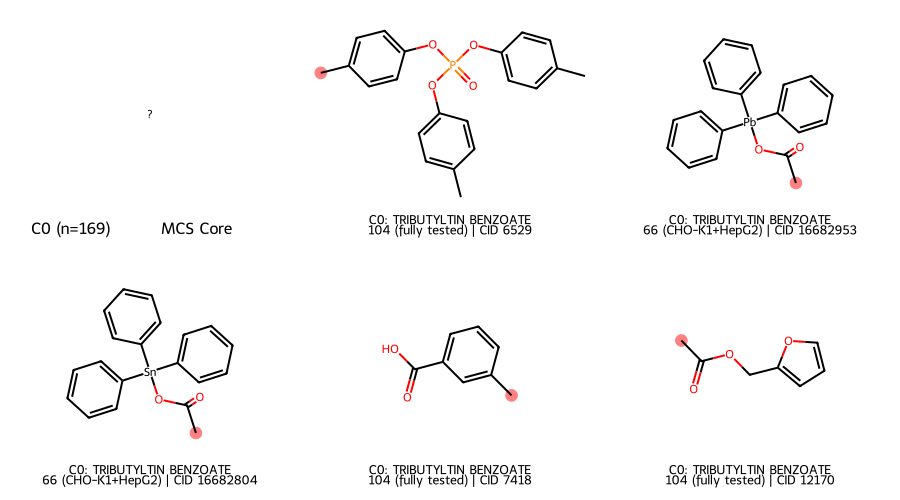

In [24]:
from IPython.display import display

CLUSTERS_170 = None
MOLS_PER_ROW = 3

cluster_ids_170 = sorted(c for c in g170['cluster'].unique() if c != -1)
if CLUSTERS_170 is not None:
    cluster_ids_170 = [c for c in cluster_ids_170 if c in CLUSTERS_170]

mols170, legs170, hi170 = [], [], []

for cl in cluster_ids_170:
    sub   = g170[g170['cluster'] == cl].reset_index(drop=True)
    shown = pick_central(sub)
    core  = get_mcs_core(shown['mol'].tolist())
    name  = cl_name_170.get(cl, f'Cluster {cl}')

    if core is not None:
        mols170.append(core)
        legs170.append(f'C{cl} (n={len(sub)}) ★ MCS Core ★')
        hi170.append([])

    for _, row in shown.iterrows():
        mol = row['mol']
        mols170.append(mol)
        legs170.append(f'C{cl}: {name}\n{row["group"]} | CID {int(row["PUBCHEM_CID"])}')
        match = mol.GetSubstructMatch(core) if core is not None else []
        hi170.append(list(match))

print(f'Drawing {len(mols170)} panels across {len(cluster_ids_170)} cluster(s)')
if mols170:
    img = Draw.MolsToGridImage(mols170, molsPerRow=MOLS_PER_ROW, subImgSize=(300, 250),
                               legends=legs170, highlightAtomLists=hi170, returnPNG=False)
    display(img)